# **Tugas Praktikum 4: Association Rule**


Nama : Sandi Suryo Nugroho

NRP : 5054251020

Dataset : Online Retail.xlsx

Pada praktikum ini, mahasiswa menemukan pola atau hubungan antar item dalam dataset transaksi menggunakan Association Rule. Aturan asosiasi diekstraksi dengan algoritma Apriori atau FP-Growth, lalu dievaluasi berdasarkan metrik support, confidence, dan lift.

## **1. Setup Library dan Dataset**


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules

# Pengaturan visualisasi dan tampilan pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
sns.set_theme(style="whitegrid")

In [5]:
file_path = 'Online Retail.xlsx'
df = pd.read_excel(file_path)

print("=== 5 Baris Pertama Dataset ===")
display(df.head())

print("\n=== Dimensi Dataset (Baris, Kolom) ===")
print(df.shape)

print("\n=== Informasi Atribut dan Tipe Data ===")
df.info()

=== 5 Baris Pertama Dataset ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



=== Dimensi Dataset (Baris, Kolom) ===
(541909, 8)

=== Informasi Atribut dan Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## **2. EDA dan Preprocessing**

In [6]:
# Hitung jumlah awal
initial_rows = len(df)
initial_invoices = df['InvoiceNo'].nunique()

# a. Pembersihan 'Description' (Hapus nilai null dan hapus spasi berlebih)
df_clean = df.dropna(subset=['Description']).copy()
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()

# b. Hapus transaksi yang dibatalkan (InvoiceNo diawali huruf 'C')
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]

# c. Hapus transaksi dengan Quantity <= 0
df_clean = df_clean[df_clean['Quantity'] > 0]

# Hitung jumlah setelah pembersihan
final_rows = len(df_clean)
final_invoices = df_clean['InvoiceNo'].nunique()

# Ringkasan hasil pembersihan data
summary_cleaning = pd.DataFrame({
    'Tahap Pembersihan': ['Sebelum Pembersihan', 'Sesudah Pembersihan', 'Jumlah Terhapus / Selisih'],
    'Jumlah Baris': [initial_rows, final_rows, initial_rows - final_rows],
    'Jumlah Unique Invoice': [initial_invoices, final_invoices, initial_invoices - final_invoices]
})

display(summary_cleaning)

,Tahap Pembersihan,Jumlah Baris,Jumlah Unique Invoice
0,Sebelum Pembersihan,541909,25900
1,Sesudah Pembersihan,530693,20136
2,Jumlah Terhapus / Selisih,11216,5764


In [7]:
# Membatasi analisis pada negara dengan transaksi terbanyak (United Kingdom) 
# untuk optimasi memori dan relevansi pola geografis
df_uk = df_clean[df_clean['Country'] == 'United Kingdom']

# Transformasi data menjadi format transaksi berbasis Invoice (Basket Format)
basket = (df_uk.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

# Ubah nilai ke dalam bentuk Boolean (One-Hot Encoded)
basket_sets = basket > 0

print(f"Dimensi matriks transaksi (Invoice x Item Description): {basket_sets.shape}")
display(basket_sets.head())

Dimensi matriks transaksi (Invoice x Item Description): (18194, 4046)


Description  *Boombox Ipod Classic  *USB Office Mirror Ball  \
InvoiceNo                                                     
536365                       False                    False   
536366                       False                    False   
536367                       False                    False   
536368                       False                    False   
536369                       False                    False   

Description  10 COLOUR SPACEBOY PEN  12 COLOURED PARTY BALLOONS  \
InvoiceNo                                                         
536365                        False                       False   
536366                        False                       False   
536367                        False                       False   
536368                        False                       False   
536369                        False                       False   

Description  12 DAISY PEGS IN WOOD BOX  12 EGG HOUSE PAINTED WOOD  \
InvoiceNo                                                           
536365                           False                      False   
536366                           False                      False   
536367                           False                      False   
536368                           False                      False   
536369                           False                      False   

Description  12 HANGING EGGS HAND PAINTED  12 IVORY ROSE PEG PLACE SETTINGS  \
InvoiceNo                                                                     
536365                              False                             False   
536366                              False                             False   
536367                              False                             False   
536368                              False                             False   
536369                              False                             False   

Description  12 MESSAGE CARDS WITH ENVELOPES  12 PENCIL SMALL TUBE WOODLAND  \
InvoiceNo                                                                     
536365                                 False                          False   
536366                                 False                          False   
536367                                 False                          False   
536368                                 False                          False   
536369                                 False                          False   

Description  12 PENCILS SMALL TUBE RED RETROSPOT  12 PENCILS SMALL TUBE SKULL  \
InvoiceNo                                                                       
536365                                     False                        False   
536366                                     False                        False   
536367                                     False                        False   
536368                                     False                        False   
536369                                     False                        False   

Description  12 PENCILS TALL TUBE POSY  12 PENCILS TALL TUBE RED RETROSPOT  \
InvoiceNo                                                                    
536365                           False                               False   
536366                           False                               False   
536367                           False                               False   
536368                           False                               False   
536369                           False                               False   

Description  12 PENCILS TALL TUBE SKULLS  12 PENCILS TALL TUBE WOODLAND  \
InvoiceNo                                                                 
536365                             False                          False   
536366                             False                          False   
536367                             False                          False   
536368

## **3. Modelling**

In [ ]:
# Penerapan Algoritma FP-Growth & Ekstraksi Aturan Asosiasi
# FP-Growth dipilih karena jauh lebih efisien dari sisi waktu komputasi dan memori dibanding Apriori standard

min_support = 0.01
min_confidence = 0.5

# Ekstraksi Frequent Itemsets
frequent_itemsets = fpgrowth(basket_sets, min_support=min_support, use_colnames=True)
frequent_itemsets = frequent_itemsets.sort_values('support', ascending=False)

print(f"Jumlah Frequent Itemsets yang ditemukan (min_support = {min_support}): {len(frequent_itemsets)}")

# Ekstraksi Association Rules berdasarkan metrik Confidence
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_confidence)
rules = rules.sort_values('lift', ascending=False)

print(f"Jumlah Aturan Asosiasi yang dihasilkan (min_confidence = {min_confidence}): {len(rules)}")
display(rules.head(10))

Jumlah Frequent Itemsets yang ditemukan (min_support = 0.01): 2131
Jumlah Aturan Asosiasi yang dihasilkan (min_confidence = 0.5): 1172


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
810,(HERB MARKER THYME),"(HERB MARKER ROSEMARY, HERB MARKER PARSLEY)",0.012642,0.011377,0.010828,0.856522,75.282882,1.0,0.010684,6.890400,0.999350,0.820833,0.854871,0.904106
809,"(HERB MARKER ROSEMARY, HERB MARKER PARSLEY)",(HERB MARKER THYME),0.011377,0.012642,0.010828,0.951691,75.282882,1.0,0.010684,20.438320,0.998072,0.820833,0.951072,0.904106
906,"(HERB MARKER THYME, HERB MARKER MINT)",(HERB MARKER ROSEMARY),0.010993,0.012696,0.010498,0.955000,75.217619,1.0,0.010358,21.940078,0.997672,0.795833,0.954421,0.890920
911,(HERB MARKER ROSEMARY),"(HERB MARKER THYME, HERB MARKER MINT)",0.012696,0.010993,0.010498,0.826840,75.217619,1.0,0.010358,5.711518,0.999394,0.795833,0.824915,0.890920
987,(HERB MARKER PARSLEY),"(HERB MARKER THYME, HERB MARKER MINT)",0.012532,0.010993,0.010333,0.824561,75.010351,1.0,0.010195,5.637342,0.999190,0.783333,0.822611,0.882281
982,"(HERB MARKER THYME, HERB MARKER MINT)",(HERB MARKER PARSLEY),0.010993,0.012532,0.010333,0.940000,75.010351,1.0,0.010195,16.457807,0.997635,0.783333,0.939239,0.882281
811,(HERB MARKER ROSEMARY),"(HERB MARKER THYME, HERB MARKER PARSLEY)",0.012696,0.011377,0.010828,0.852814,74.956982,1.0,0.010683,6.716818,0.999347,0.817427,0.851120,0.902252
808,"(HERB MARKER THYME, HERB MARKER PARSLEY)",(HERB MARKER ROSEMARY),0.011377,0.012696,0.010828,0.951691,74.956982,1.0,0.010683,20.437183,0.998014,0.817427,0.951070,0.902252
866,"(HERB MARKER THYME, HERB MARKER BASIL)",(HERB MARKER ROSEMARY),0.011158,0.012696,0.010608,0.950739,74.882008,1.0,0.010466,20.042261,0.997778,0.800830,0.950105,0.893118
871,(HERB MARKER ROSEMARY),"(HERB MARKER THYME, HERB MARKER BASIL)",0.012696,0.011158,0.010608,0.835498,74.882008,1.0,0.010466,6.011121,0.999334,0.800830,0.833642,0.893118


## **4. Evaluasi Model**

In [ ]:
top_3_rules = rules.head(3).copy()

# Konversi frozenset ke list untuk kemudahan pembacaan tabel
top_3_rules['antecedents'] = top_3_rules['antecedents'].apply(lambda x: list(x))
top_3_rules['consequents'] = top_3_rules['consequents'].apply(lambda x: list(x))

display_cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print("=== TOP 3 ASSOCIATION RULES BERDASARKAN LIFT ===")
display(top_3_rules[display_cols])

=== TOP 3 ASSOCIATION RULES BERDASARKAN LIFT ===


,antecedents,consequents,support,confidence,lift
810,[HERB MARKER THYME],"[HERB MARKER ROSEMARY, HERB MARKER PARSLEY]",0.010828,0.856522,75.282882
809,"[HERB MARKER ROSEMARY, HERB MARKER PARSLEY]",[HERB MARKER THYME],0.010828,0.951691,75.282882
906,"[HERB MARKER THYME, HERB MARKER MINT]",[HERB MARKER ROSEMARY],0.010498,0.955000,75.217619


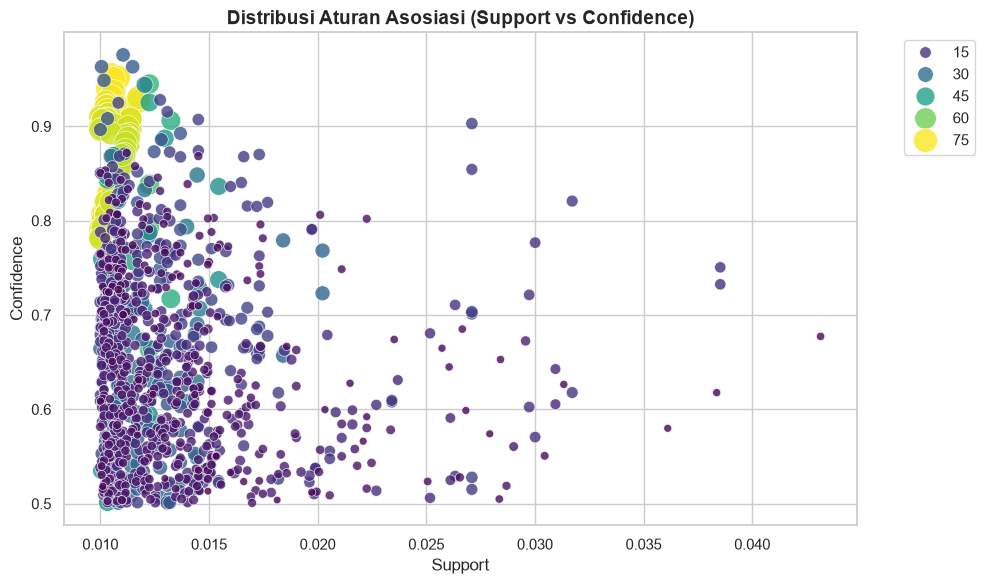

In [10]:
# Visualisasi Aturan Asosiasi (Support vs Confidence berwarna Lift)
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(
    data=rules, 
    x='support', 
    y='confidence', 
    size='lift', 
    hue='lift', 
    palette='viridis', 
    sizes=(30, 300),
    alpha=0.8
)

plt.title('Distribusi Aturan Asosiasi (Support vs Confidence)', fontsize=14, fontweight='bold')
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## **6. Analisis**


## 1. Eksplorasi & Pembersihan Data

**Pembersihan** 
Menghapus `Description` kosong, transaksi pembatalan (`InvoiceNo` berawalan "C"), serta `Quantity` $\le 0$.


| Tahap Pembersihan | Jumlah Baris | Unique Invoice |
| --- | --- | --- |
| Sebelum Pembersihan | 541.909 | 25.900 |
| Sesudah Pembersihan | 530.693 | 20.136 |
| **Jumlah Terhapus / Selisih** | **11.216** | **5.764** |

## 2. Aturan Asosiasi & Evaluasi

Menggunakan **FP-Growth** ($min\_support = 0.01$, $min\_confidence = 0.50$), dihasilkan **2.131 itemsets** dan **1.172 rules**.

**Top 3 Aturan Asosiasi (Berdasarkan Lift):**

| No | Antecedents | Consequents | Support | Confidence | Lift |
| --- | --- | --- | --- | --- | --- |
| **1** | `[HERB MARKER THYME]` | `[HERB MARKER ROSEMARY, PARSLEY]` | 0,0108 | 85,65% | **75,28** |
| **2** | `[HERB MARKER ROSEMARY, PARSLEY]` | `[HERB MARKER THYME]` | 0,0108 | 95,17% | **75,28** |
| **3** | `[HERB MARKER THYME, MINT]` | `[HERB MARKER ROSEMARY]` | 0,0105 | 95,50% | **75,22** |

*Support* $\approx 1,05\% - 1,08\%$, *Confidence* tinggi ($85,65\% - 95,50\%$), dan *Lift* $\gg 1$ ($75,22 - 75,28$) membuktikan keterikatan kuat antar-item komplementer (bukan acak).

## 3. Kesimpulan & Rekomendasi

 Pelanggan cenderung membeli seluruh varian produk bertema sama (seperti set penanda tanaman *Herb Markers*) dalam satu transaksi.


* **Aksi Bisnis:**
1. Buat paket *"Complete Herb Garden Kit"*.

2. Tampilkan item pasangan di fitur *"Frequently Bought Together"*.

3. Jaga ketersediaan inventaris varian komplementer agar selalu seimbang.